# DX799 O1 - Week 3 Jupyter Notebook: Feature Selection, PCR, and PLSR

## Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Goal of this notebook

Week 3 is about simplifying a linear regression model in two very different ways.

- **Forward and backward selection** keep the original variables visible and ask which ones are worth retaining.
- **Principal Component Regression (PCR)** replaces the original predictors with directions that explain variation in the predictor matrix.
- **Partial Least Squares Regression (PLSR)** also builds components, but it uses the outcome while deciding which directions are useful.

I use all four cleaned datasets, but I do not repeat every method four times. The datasets answer different parts of the same project:

- **Behavior** and **Churn** are used for forward/backward selection because the original business variables are meaningful to a decision-maker.
- **Products** and **Reviews** are used for PCR versus PLSR because these tables are good places to ask whether a smaller latent representation can preserve prediction.

This keeps the notebook aligned with the project while also making the Week 3 concepts easier to interpret.

## 1. Questions I want Week 3 to answer

1. Can I remove behavior predictors and still predict `Profit` about as well as the full model?
2. Which customer-activity variables are consistently retained when predicting `OrderCount`?
3. Do forward and backward selection converge on the same subset even though they start from opposite directions?
4. How many principal components are needed before PCR becomes competitive for product demand and review sentiment?
5. Can PLSR reach similar prediction with fewer components because it uses the outcome while constructing them?
6. Which method gives the best tradeoff between **prediction, simplicity, and interpretability**?

I use training, validation, and test partitions. The validation set is used for model-size decisions. The test set stays untouched until those decisions are fixed.

## 2. Week 3 concepts I am applying

### Forward selection

Forward selection starts with no predictors. At each step, I add the remaining feature that gives the lowest validation RMSE.

### Backward selection

Backward selection starts with all candidate predictors. At each step, I remove the feature whose removal gives the lowest validation RMSE.

Both are **greedy procedures**. They do not test every possible subset, so agreement between them is useful evidence but not proof of a globally optimal feature set.

### PCR

PCR standardizes the predictor matrix, applies PCA, and then fits linear regression to the retained principal components. The important limitation from the lecture is that PCA ranks directions by **predictor variance**, not by usefulness for predicting the outcome.

If every principal component is retained, PCR should behave like the full linear regression apart from numerical details. PCR only changes the problem when some components are removed.

### PLSR

PLSR also creates a smaller component representation, but it uses the outcome while finding the components. This means it can sometimes reach a useful predictive representation with fewer components than PCR.

I standardize the model inputs because both PCR and PLSR are sensitive to scale.

In [1]:
# Imports and reproducibility

from pathlib import Path
import re
import json
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 3. Load the four cleaned datasets

The four datasets remain at their valid grains rather than being force-joined.

- Behavior is order/activity level.
- Churn is customer level.
- Products is product level.
- Reviews is review level.

Behavior and reviews contain repeated entities, so their train/test splits are grouped by customer and product respectively. That prevents the same entity from appearing on both sides of a split.

In [2]:
candidate_dirs = [
    Path("data"),
    Path("../data"),
    Path("data_pkg"),
    Path("../data_pkg"),
    Path("/mnt/data/dx799_rebuild/data/cleaned_week2_output"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "behavior_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError("Could not find the four cleaned CSV files.")

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

print(f"Loaded data from: {DATA_DIR}")

Loaded data from: data


In [3]:
# Parse the product/review fields used in the Week 3 component models.

products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    match = re.search(r"([\d,.]+)\s*([Kk]?)", str(value))
    if not match:
        return np.nan

    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)

products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)

products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"])
    / products["list_price_num"],
    0,
)

products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)

products["in_stock"] = (
    products["availability"]
    .astype(str)
    .str.lower()
    .str.contains("in stock")
    .astype(int)
)

products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()
products["log_rating_count"] = np.log1p(products["rating_count_num"])

reviews["review_len"] = (
    reviews["cleaned_review_text"].astype(str).str.split().str.len()
)
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)

In [4]:
dataset_roles = pd.DataFrame(
    {
        "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
        "Rows": [len(behavior), len(churn), len(products), len(reviews)],
        "Grain": ["order/activity", "customer", "product", "review"],
        "Week 3 method": [
            "Forward + backward selection",
            "Forward + backward selection",
            "PCR + PLSR",
            "PCR + PLSR",
        ],
        "Outcome": [
            "Profit",
            "OrderCount",
            "log(1 + rating count)",
            "sentiment_score",
        ],
        "Reason for method choice": [
            "retain interpretable transaction drivers",
            "retain interpretable customer-activity drivers",
            "test compact latent demand representation",
            "test compact latent post-purchase representation",
        ],
    }
)

display(dataset_roles)

,Dataset,Rows,Grain,Week 3 method,Outcome,Reason for method choice
0,Behavior,51289,order/activity,Forward + backward selection,Profit,retain interpretable transaction drivers
1,Churn,5630,customer,Forward + backward selection,OrderCount,retain interpretable customer-activity drivers
2,Products,728,product,PCR + PLSR,log(1 + rating count),test compact latent demand representation
3,Reviews,6327,review,PCR + PLSR,sentiment_score,test compact latent post-purchase representation


## 4. Part A: Forward and backward selection

I use a compact set of original numeric predictors for the two stepwise tasks. This is deliberate.

If I first one-hot encode many categories, the selection path can become dominated by individual dummy levels. For this Week 3 exercise, I want the selected variables to remain easy to explain in business terms.

### Behavior target: `Profit`

Candidate predictors:

- `Sales`
- `Quantity`
- `Discount`
- `Browsing Time (min)`
- `Age`

### Churn-table target: `OrderCount`

Candidate predictors include tenure, recency, coupon usage, cashback, complaints, addresses, app usage, and other activity measures.

Before running the selection algorithms, I look at simple correlations with the target as an EDA reference point.

In [5]:
STEP_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Profit",
        "group": "Customer ID",
        "features": [
            "Sales",
            "Quantity",
            "Discount",
            "Browsing Time (min)",
            "Age",
        ],
    },
    "Churn": {
        "df": churn,
        "target": "OrderCount",
        "group": None,
        "features": [
            "Tenure",
            "WarehouseToHome",
            "HourSpendOnApp",
            "NumberOfDeviceRegistered",
            "SatisfactionScore",
            "NumberOfAddress",
            "Complain",
            "OrderAmountHikeFromlastYear",
            "CouponUsed",
            "DaySinceLastOrder",
            "CashbackAmount",
        ],
    },
}

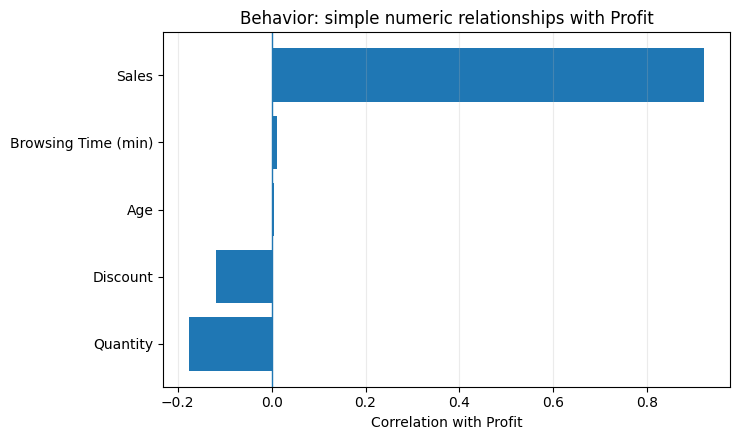

,Correlation with Profit
Quantity,-0.1763
Discount,-0.1190
Age,0.0043
Browsing Time (min),0.0106
Sales,0.9215


In [6]:
# Correlation screen for Behavior.

behavior_corr = (
    behavior[
        STEP_TASKS["Behavior"]["features"]
        + [STEP_TASKS["Behavior"]["target"]]
    ]
    .corr(numeric_only=True)[STEP_TASKS["Behavior"]["target"]]
    .drop(STEP_TASKS["Behavior"]["target"])
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(behavior_corr.index, behavior_corr.values)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Correlation with Profit")
ax.set_title("Behavior: simple numeric relationships with Profit")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(behavior_corr.to_frame("Correlation with Profit").round(4))

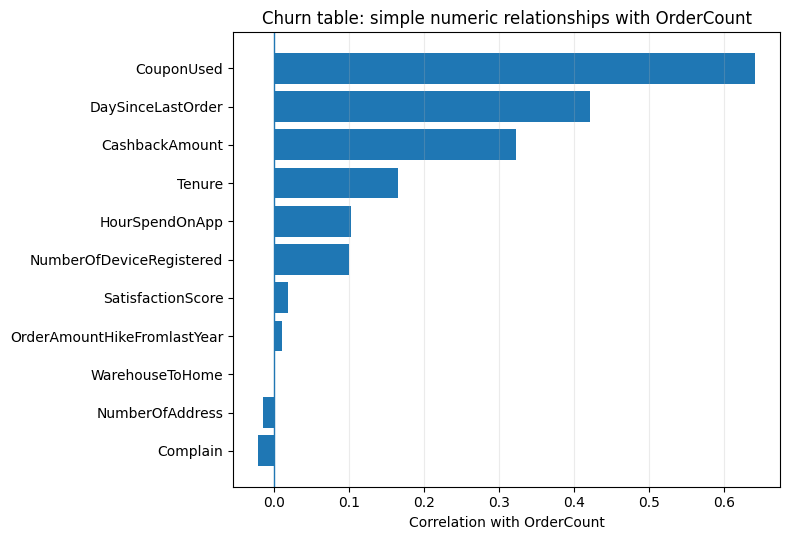

,Correlation with OrderCount
Complain,-0.0213
NumberOfAddress,-0.0140
WarehouseToHome,0.0004
OrderAmountHikeFromlastYear,0.0106
SatisfactionScore,0.0182
NumberOfDeviceRegistered,0.0998
HourSpendOnApp,0.1021
Tenure,0.1653
CashbackAmount,0.3223
DaySinceLastOrder,0.4216


In [7]:
# Correlation screen for Churn-table OrderCount.

churn_corr = (
    churn[
        STEP_TASKS["Churn"]["features"]
        + [STEP_TASKS["Churn"]["target"]]
    ]
    .corr(numeric_only=True)[STEP_TASKS["Churn"]["target"]]
    .drop(STEP_TASKS["Churn"]["target"])
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(churn_corr.index, churn_corr.values)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Correlation with OrderCount")
ax.set_title("Churn table: simple numeric relationships with OrderCount")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(churn_corr.to_frame("Correlation with OrderCount").round(4))

### EDA observations before selection

The behavior table is dominated by the transaction economics variables. `Sales`, `Quantity`, and `Discount` are much more directly related to profit than browsing time or age.

The churn-table activity model is less concentrated. `CouponUsed`, `DaySinceLastOrder`, and `CashbackAmount` are among the strongest simple relationships with `OrderCount`, but several other customer variables may still matter after the stronger predictors are controlled.

I use these correlations only as a reference. The selection algorithms are evaluated on validation RMSE, not on pairwise correlation.

## 5. Train, validation, and test design

For both stepwise tasks:

- training data fit the candidate models
- validation data choose the number of retained variables
- test data are used once after the selected subset is fixed

Behavior is split by `Customer ID` so records from the same customer do not leak across partitions.

Numeric predictors are median-imputed if needed and standardized using the training data.

In [8]:
def split_three(df, group_col=None):
    idx = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values

        first = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )
        train_validation, test = next(
            first.split(idx, groups=groups)
        )

        second = GroupShuffleSplit(
            n_splits=1,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
        )
        train_relative, validation_relative = next(
            second.split(
                train_validation,
                groups=groups[train_validation],
            )
        )

        train = train_validation[train_relative]
        validation = train_validation[validation_relative]

    else:
        train_validation, test = train_test_split(
            idx,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )

        train, validation = train_test_split(
            train_validation,
            test_size=0.25,
            random_state=RANDOM_STATE + 1,
        )

    return train, validation, test


def regression_metrics(y_true, prediction):
    return {
        "RMSE": mean_squared_error(y_true, prediction) ** 0.5,
        "MAE": mean_absolute_error(y_true, prediction),
        "R2": r2_score(y_true, prediction),
    }

In [9]:
def forward_selection_path(X_train, y_train, X_validation, y_validation):
    remaining = list(X_train.columns)
    selected = []
    path = []

    while remaining:
        candidates = []

        for feature in remaining:
            trial_features = selected + [feature]

            model = LinearRegression().fit(
                X_train[trial_features],
                y_train,
            )

            prediction = model.predict(
                X_validation[trial_features]
            )

            rmse = mean_squared_error(
                y_validation,
                prediction,
            ) ** 0.5

            candidates.append((rmse, feature))

        best_rmse, best_feature = min(candidates)

        selected.append(best_feature)
        remaining.remove(best_feature)

        path.append(
            {
                "n_features": len(selected),
                "validation_RMSE": best_rmse,
                "feature_added": best_feature,
                "features": selected.copy(),
            }
        )

    return path


def backward_selection_path(X_train, y_train, X_validation, y_validation):
    selected = list(X_train.columns)
    path = []

    full_model = LinearRegression().fit(
        X_train[selected],
        y_train,
    )

    full_prediction = full_model.predict(
        X_validation[selected]
    )

    path.append(
        {
            "n_features": len(selected),
            "validation_RMSE": mean_squared_error(
                y_validation,
                full_prediction,
            ) ** 0.5,
            "feature_removed": None,
            "features": selected.copy(),
        }
    )

    while len(selected) > 1:
        candidates = []

        for feature in selected:
            trial_features = [
                value for value in selected
                if value != feature
            ]

            model = LinearRegression().fit(
                X_train[trial_features],
                y_train,
            )

            prediction = model.predict(
                X_validation[trial_features]
            )

            rmse = mean_squared_error(
                y_validation,
                prediction,
            ) ** 0.5

            candidates.append(
                (rmse, feature, trial_features)
            )

        best_rmse, removed, best_features = min(
            candidates,
            key=lambda row: row[0],
        )

        selected = best_features

        path.append(
            {
                "n_features": len(selected),
                "validation_RMSE": best_rmse,
                "feature_removed": removed,
                "features": selected.copy(),
            }
        )

    return path

In [10]:
stepwise_results = {}
stepwise_paths = {}

for dataset_name, task in STEP_TASKS.items():
    df = task["df"]
    features = task["features"]
    target = task["target"]

    train_idx, validation_idx, test_idx = split_three(
        df,
        task["group"],
    )

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train_raw = imputer.fit_transform(
        df.iloc[train_idx][features]
    )
    X_validation_raw = imputer.transform(
        df.iloc[validation_idx][features]
    )
    X_test_raw = imputer.transform(
        df.iloc[test_idx][features]
    )

    X_train = pd.DataFrame(
        scaler.fit_transform(X_train_raw),
        columns=features,
        index=df.iloc[train_idx].index,
    )
    X_validation = pd.DataFrame(
        scaler.transform(X_validation_raw),
        columns=features,
        index=df.iloc[validation_idx].index,
    )
    X_test = pd.DataFrame(
        scaler.transform(X_test_raw),
        columns=features,
        index=df.iloc[test_idx].index,
    )

    y_train = df.iloc[train_idx][target].astype(float)
    y_validation = df.iloc[validation_idx][target].astype(float)
    y_test = df.iloc[test_idx][target].astype(float)

    # Full model validation baseline
    baseline = LinearRegression().fit(X_train, y_train)
    baseline_validation_prediction = baseline.predict(X_validation)
    baseline_validation_rmse = mean_squared_error(
        y_validation,
        baseline_validation_prediction,
    ) ** 0.5

    forward_path = forward_selection_path(
        X_train,
        y_train,
        X_validation,
        y_validation,
    )

    backward_path = backward_selection_path(
        X_train,
        y_train,
        X_validation,
        y_validation,
    )

    forward_best = min(
        forward_path,
        key=lambda row: row["validation_RMSE"],
    )
    backward_best = min(
        backward_path,
        key=lambda row: row["validation_RMSE"],
    )

    stepwise_paths[dataset_name] = {
        "forward": forward_path,
        "backward": backward_path,
    }

    stepwise_results[dataset_name] = {
        "train_idx": train_idx,
        "validation_idx": validation_idx,
        "test_idx": test_idx,
        "imputer": imputer,
        "scaler": scaler,
        "X_train": X_train,
        "X_validation": X_validation,
        "X_test": X_test,
        "y_train": y_train,
        "y_validation": y_validation,
        "y_test": y_test,
        "baseline_validation_RMSE": baseline_validation_rmse,
        "forward_best": forward_best,
        "backward_best": backward_best,
    }

summary_rows = []

for dataset_name, info in stepwise_results.items():
    for method_name, best in [
        ("Forward", info["forward_best"]),
        ("Backward", info["backward_best"]),
    ]:
        summary_rows.append(
            {
                "Dataset": dataset_name,
                "Method": method_name,
                "Selected features": best["n_features"],
                "Validation RMSE": best["validation_RMSE"],
                "Full-model validation RMSE": info["baseline_validation_RMSE"],
            }
        )

stepwise_validation_summary = pd.DataFrame(summary_rows)
display(stepwise_validation_summary.round(4))

,Dataset,Method,Selected features,Validation RMSE,Full-model validation RMSE
0,Behavior,Forward,3,16.1756,16.1796
1,Behavior,Backward,3,16.1756,16.1796
2,Churn,Forward,6,2.0217,2.0255
3,Churn,Backward,6,2.0217,2.0255


## 6. Forward and backward validation paths

The full path is more useful than reporting only the final subset.

A useful feature-selection method should not just reduce the number of variables. It should show **where validation error stops improving**.

I plot the forward and backward paths separately for each dataset so the scale remains readable.

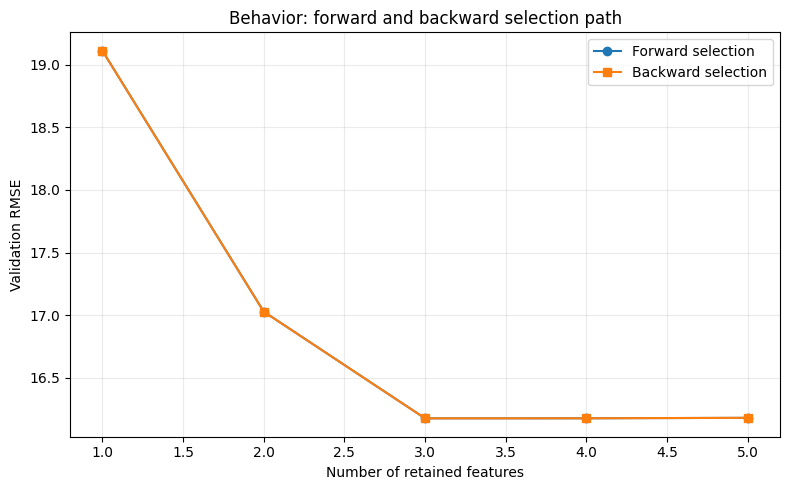

In [11]:
# Behavior selection path.

behavior_forward = pd.DataFrame(
    stepwise_paths["Behavior"]["forward"]
)
behavior_backward = pd.DataFrame(
    stepwise_paths["Behavior"]["backward"]
).sort_values("n_features")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    behavior_forward["n_features"],
    behavior_forward["validation_RMSE"],
    marker="o",
    label="Forward selection",
)
ax.plot(
    behavior_backward["n_features"],
    behavior_backward["validation_RMSE"],
    marker="s",
    label="Backward selection",
)

ax.set_xlabel("Number of retained features")
ax.set_ylabel("Validation RMSE")
ax.set_title("Behavior: forward and backward selection path")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

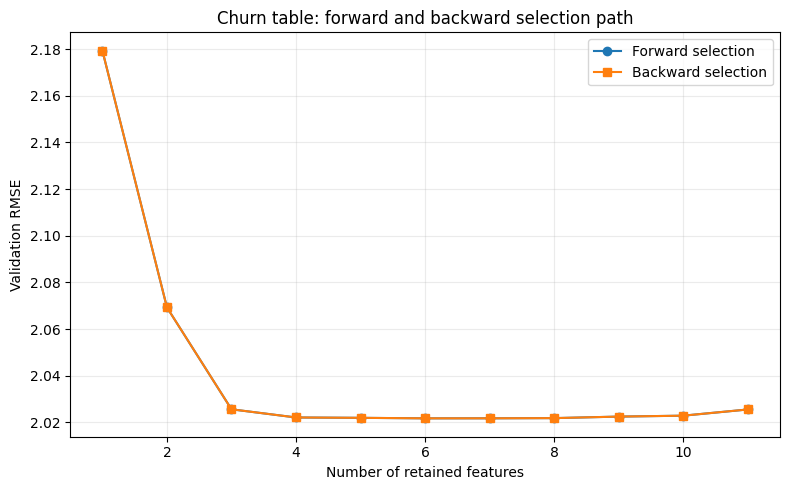

In [12]:
# Churn-table selection path.

churn_forward = pd.DataFrame(
    stepwise_paths["Churn"]["forward"]
)
churn_backward = pd.DataFrame(
    stepwise_paths["Churn"]["backward"]
).sort_values("n_features")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    churn_forward["n_features"],
    churn_forward["validation_RMSE"],
    marker="o",
    label="Forward selection",
)
ax.plot(
    churn_backward["n_features"],
    churn_backward["validation_RMSE"],
    marker="s",
    label="Backward selection",
)

ax.set_xlabel("Number of retained features")
ax.set_ylabel("Validation RMSE")
ax.set_title("Churn table: forward and backward selection path")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# Show the actual best subsets.

for dataset_name, info in stepwise_results.items():
    print(f"\n{dataset_name}")

    print(
        "Forward selected:",
        info["forward_best"]["features"],
    )

    print(
        "Backward selected:",
        info["backward_best"]["features"],
    )

    overlap = set(info["forward_best"]["features"]) & set(
        info["backward_best"]["features"]
    )

    union = set(info["forward_best"]["features"]) | set(
        info["backward_best"]["features"]
    )

    print(
        f"Overlap: {len(overlap)} of {len(union)} unique selected features"
    )


Behavior
Forward selected: ['Sales', 'Quantity', 'Discount']
Backward selected: ['Sales', 'Quantity', 'Discount']
Overlap: 3 of 3 unique selected features

Churn
Forward selected: ['CouponUsed', 'DaySinceLastOrder', 'CashbackAmount', 'NumberOfAddress', 'HourSpendOnApp', 'OrderAmountHikeFromlastYear']
Backward selected: ['HourSpendOnApp', 'NumberOfAddress', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'DaySinceLastOrder', 'CashbackAmount']
Overlap: 6 of 6 unique selected features


### What stood out

Both directions converge on the same final subset in each dataset.

- **Behavior:** both methods retain `Sales`, `Quantity`, and `Discount`.
- **Churn:** both retain the same seven customer-activity variables, although the order of entry/removal differs.

That agreement is useful because forward and backward selection start from opposite ends of the search space. It still does not guarantee a globally optimal subset because neither method evaluates every possible combination.

The behavior result is especially easy to explain: transaction economics variables dominate, while `Browsing Time (min)` and `Age` do not improve validation RMSE once sales, quantity, and discount are present.

## 7. Final stepwise comparison on the untouched test set

The subset size has now been chosen.

I refit each selected specification using the combined training and validation data and evaluate it once on the test set. I also refit the full model using the same combined data so the comparison is fair.

In [14]:
stepwise_test_rows = []
selected_coefficient_tables = {}

for dataset_name, task in STEP_TASKS.items():
    info = stepwise_results[dataset_name]

    train_validation_idx = np.concatenate(
        [info["train_idx"], info["validation_idx"]]
    )
    test_idx = info["test_idx"]

    features = task["features"]
    target = task["target"]
    df = task["df"]

    final_imputer = SimpleImputer(strategy="median")
    final_scaler = StandardScaler()

    X_train_validation_raw = final_imputer.fit_transform(
        df.iloc[train_validation_idx][features]
    )
    X_test_raw = final_imputer.transform(
        df.iloc[test_idx][features]
    )

    X_train_validation = pd.DataFrame(
        final_scaler.fit_transform(X_train_validation_raw),
        columns=features,
    )
    X_test = pd.DataFrame(
        final_scaler.transform(X_test_raw),
        columns=features,
    )

    y_train_validation = df.iloc[train_validation_idx][target].astype(float)
    y_test = df.iloc[test_idx][target].astype(float)

    full_model = LinearRegression().fit(
        X_train_validation,
        y_train_validation,
    )

    full_prediction = full_model.predict(X_test)

    stepwise_test_rows.append(
        {
            "Dataset": dataset_name,
            "Model": "Full OLS",
            "Complexity": len(features),
            **regression_metrics(y_test, full_prediction),
        }
    )

    for method_name, best in [
        ("Forward", info["forward_best"]),
        ("Backward", info["backward_best"]),
    ]:
        selected = best["features"]

        model = LinearRegression().fit(
            X_train_validation[selected],
            y_train_validation,
        )

        prediction = model.predict(
            X_test[selected]
        )

        stepwise_test_rows.append(
            {
                "Dataset": dataset_name,
                "Model": method_name,
                "Complexity": len(selected),
                **regression_metrics(y_test, prediction),
            }
        )

        selected_coefficient_tables[
            (dataset_name, method_name)
        ] = pd.DataFrame(
            {
                "Feature": selected,
                "Coefficient": model.coef_,
            }
        ).sort_values(
            "Coefficient",
            key=lambda s: s.abs(),
            ascending=False,
        )

stepwise_test_results = pd.DataFrame(stepwise_test_rows)
display(stepwise_test_results.round(4))

,Dataset,Model,Complexity,RMSE,MAE,R2
0,Behavior,Full OLS,5,16.1314,12.8586,0.8921
1,Behavior,Forward,3,16.1324,12.8590,0.8921
2,Behavior,Backward,3,16.1324,12.8590,0.8921
3,Churn,Full OLS,11,2.1085,1.2887,0.4546
4,Churn,Forward,6,2.1091,1.2875,0.4543
5,Churn,Backward,6,2.1091,1.2875,0.4543


,Dataset,Full predictors,Selected predictors,Predictors removed,RMSE change vs full,R2 change vs full
0,Behavior,5,3,2,0.0010,-0.0000
1,Churn,11,6,5,0.0007,-0.0003


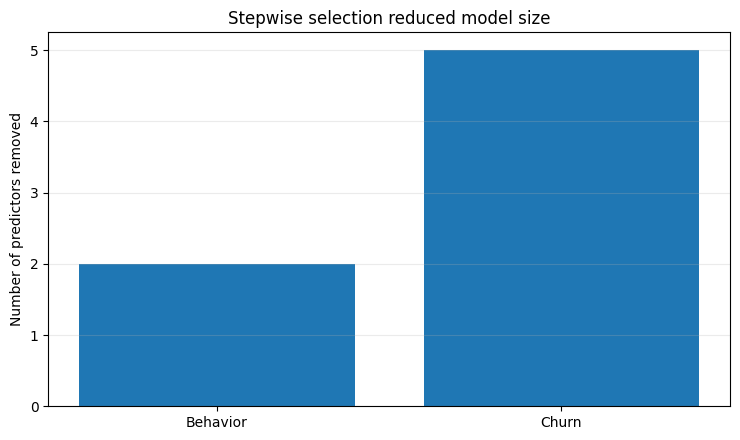

In [15]:
# How much complexity was removed without changing test RMSE much?

complexity_summary = []

for dataset_name in STEP_TASKS:
    subset = stepwise_test_results[
        stepwise_test_results["Dataset"] == dataset_name
    ]

    full_row = subset[subset["Model"] == "Full OLS"].iloc[0]
    selected_row = subset[subset["Model"] == "Forward"].iloc[0]

    complexity_summary.append(
        {
            "Dataset": dataset_name,
            "Full predictors": int(full_row["Complexity"]),
            "Selected predictors": int(selected_row["Complexity"]),
            "Predictors removed": int(
                full_row["Complexity"] - selected_row["Complexity"]
            ),
            "RMSE change vs full": (
                selected_row["RMSE"] - full_row["RMSE"]
            ),
            "R2 change vs full": (
                selected_row["R2"] - full_row["R2"]
            ),
        }
    )

complexity_summary = pd.DataFrame(complexity_summary)
display(complexity_summary.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(
    complexity_summary["Dataset"],
    complexity_summary["Predictors removed"],
)
ax.set_ylabel("Number of predictors removed")
ax.set_title("Stepwise selection reduced model size")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Stepwise decision

For both stepwise tasks, the main value is **simplification rather than a large accuracy gain**.

- Behavior reduces five original numeric predictors to three.
- Churn reduces eleven original numeric predictors to seven.

The selected models remain close to the full model on the untouched test set. That makes the smaller specifications attractive when interpretability matters.

Because the selected variables remain original business features, this is easier to explain to a stakeholder than a latent-component model.

## 8. Interpreting the selected original variables

The coefficients below are from standardized predictors, so their relative magnitude is easier to compare within each model.

They are descriptive associations, not causal effects.

In [16]:
print("Behavior selected model")
display(
    selected_coefficient_tables[
        ("Behavior", "Forward")
    ].round(4)
)

print("Churn-table selected model")
display(
    selected_coefficient_tables[
        ("Churn", "Forward")
    ].round(4)
)

Behavior selected model


,Feature,Coefficient
0,Sales,45.1877
1,Quantity,-8.5699
2,Discount,-5.4758


Churn-table selected model


,Feature,Coefficient
0,CouponUsed,1.6108
1,DaySinceLastOrder,0.5985
2,CashbackAmount,0.4223
3,NumberOfAddress,-0.1271
4,HourSpendOnApp,-0.0606
5,OrderAmountHikeFromlastYear,0.0198


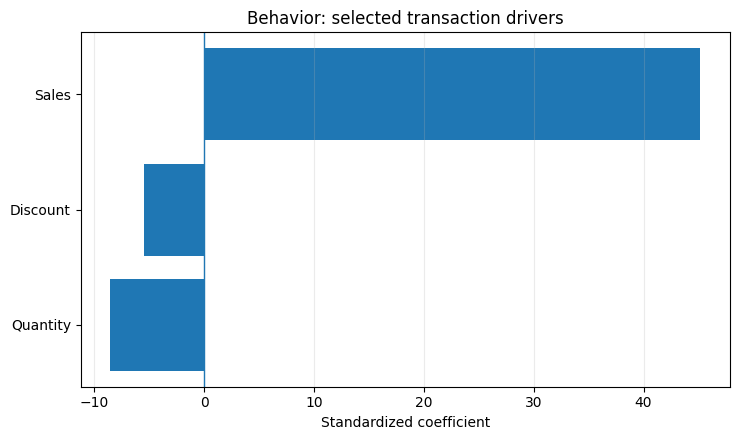

In [17]:
behavior_selected = (
    selected_coefficient_tables[
        ("Behavior", "Forward")
    ]
    .sort_values("Coefficient")
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(
    behavior_selected["Feature"],
    behavior_selected["Coefficient"],
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Behavior: selected transaction drivers")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

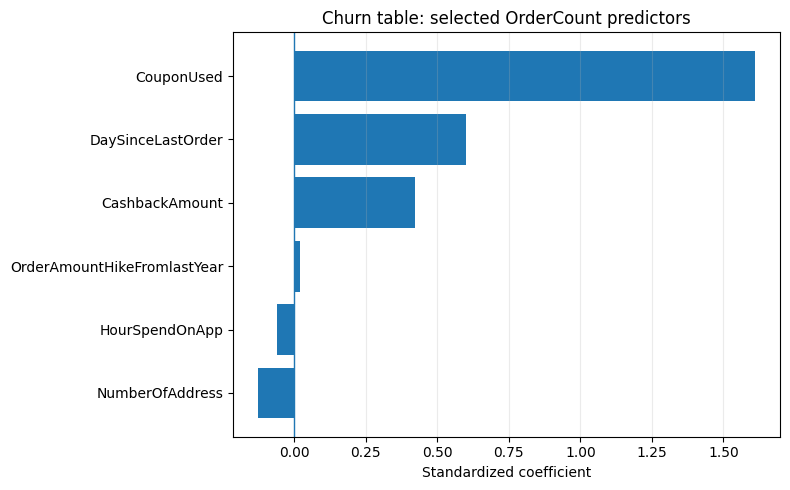

In [18]:
churn_selected = (
    selected_coefficient_tables[
        ("Churn", "Forward")
    ]
    .sort_values("Coefficient")
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(
    churn_selected["Feature"],
    churn_selected["Coefficient"],
)
ax.axvline(0, linewidth=1)
ax.set_xlabel("Standardized coefficient")
ax.set_title("Churn table: selected OrderCount predictors")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Part B: PCR and PLSR

I use the **Products** and **Reviews** tables for the dimensionality-reduction part of Week 3.

### Products outcome

`log_rating_count` is used as a stabilized measure of accumulated product attention.

### Reviews outcome

`sentiment_score` is used as a continuous post-purchase experience measure.

Both models start from the same encoded and standardized feature matrix so the comparison is fair.

For PCR, I also track cumulative explained variance. That lets me separate two questions:

- how much predictor variance has been retained?
- how much predictive performance has been retained?

Those are not the same thing, and the lecture specifically warns that high-variance directions are not guaranteed to be the most predictive.

In [19]:
COMPONENT_TASKS = {
    "Products": {
        "df": products,
        "target": "log_rating_count",
        "group": None,
        "numeric": [
            "price_value",
            "rating_stars_num",
            "recent_purchases_num",
            "discount_pct",
            "main_rank",
            "rank_1",
            "description_len",
            "review_summary_len",
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "sentiment_score",
        "group": "productASIN",
        "numeric": [
            "rating",
            "helpfulVoteCount",
            "reviewPosition",
            "review_len",
            "verified_int",
        ],
        "categorical": [],
    },
}

In [20]:
def make_component_preprocessor(task):
    transformers = []

    numeric_pipe = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median")),
        ]
    )

    transformers.append(
        ("num", numeric_pipe, task["numeric"])
    )

    if task["categorical"]:
        categorical_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        drop="first",
                        sparse_output=False,
                    ),
                ),
            ]
        )

        transformers.append(
            ("cat", categorical_pipe, task["categorical"])
        )

    return ColumnTransformer(transformers)

In [21]:
component_results = {}
component_curves = {}
component_baselines = {}

for dataset_name, task in COMPONENT_TASKS.items():
    df = task["df"]

    train_idx, validation_idx, test_idx = split_three(
        df,
        task["group"],
    )

    features = task["numeric"] + task["categorical"]

    preprocessor = make_component_preprocessor(task)

    X_train_raw = preprocessor.fit_transform(
        df.iloc[train_idx][features]
    )
    X_validation_raw = preprocessor.transform(
        df.iloc[validation_idx][features]
    )
    X_test_raw = preprocessor.transform(
        df.iloc[test_idx][features]
    )

    # Standardize the full encoded matrix so PCA/PLS are not dominated by scale.
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train_raw)
    X_validation = scaler.transform(X_validation_raw)
    X_test = scaler.transform(X_test_raw)

    y_train = df.iloc[train_idx][task["target"]].astype(float).values
    y_validation = df.iloc[validation_idx][task["target"]].astype(float).values
    y_test = df.iloc[test_idx][task["target"]].astype(float).values

    feature_names = preprocessor.get_feature_names_out()

    # Full OLS validation baseline.
    baseline = LinearRegression().fit(
        X_train,
        y_train,
    )

    baseline_validation = baseline.predict(
        X_validation
    )

    baseline_validation_rmse = mean_squared_error(
        y_validation,
        baseline_validation,
    ) ** 0.5

    max_components = min(
        X_train.shape[1],
        X_train.shape[0] - 1,
    )

    # PCA once for explained-variance diagnostics.
    full_pca = PCA(
        n_components=max_components
    ).fit(X_train)

    cumulative_variance = np.cumsum(
        full_pca.explained_variance_ratio_
    )

    rows = []

    for n_components in range(
        1,
        max_components + 1,
    ):
        pca = PCA(
            n_components=n_components
        ).fit(X_train)

        pcr_model = LinearRegression().fit(
            pca.transform(X_train),
            y_train,
        )

        pcr_validation_prediction = pcr_model.predict(
            pca.transform(X_validation)
        )

        pcr_rmse = mean_squared_error(
            y_validation,
            pcr_validation_prediction,
        ) ** 0.5

        pls_model = PLSRegression(
            n_components=n_components,
            scale=False,
        ).fit(
            X_train,
            y_train,
        )

        pls_validation_prediction = (
            pls_model.predict(X_validation).ravel()
        )

        pls_rmse = mean_squared_error(
            y_validation,
            pls_validation_prediction,
        ) ** 0.5

        rows.append(
            {
                "n_components": n_components,
                "Method": "PCR",
                "Validation RMSE": pcr_rmse,
                "Cumulative predictor variance": cumulative_variance[
                    n_components - 1
                ],
            }
        )

        rows.append(
            {
                "n_components": n_components,
                "Method": "PLSR",
                "Validation RMSE": pls_rmse,
                "Cumulative predictor variance": np.nan,
            }
        )

    curve = pd.DataFrame(rows)

    best_pcr = (
        curve[curve["Method"] == "PCR"]
        .sort_values("Validation RMSE")
        .iloc[0]
    )

    best_plsr = (
        curve[curve["Method"] == "PLSR"]
        .sort_values("Validation RMSE")
        .iloc[0]
    )

    component_results[dataset_name] = {
        "train_idx": train_idx,
        "validation_idx": validation_idx,
        "test_idx": test_idx,
        "feature_names": feature_names,
        "baseline_validation_RMSE": baseline_validation_rmse,
        "best_PCR_components": int(best_pcr["n_components"]),
        "best_PCR_validation_RMSE": float(best_pcr["Validation RMSE"]),
        "best_PCR_variance": float(
            best_pcr["Cumulative predictor variance"]
        ),
        "best_PLSR_components": int(best_plsr["n_components"]),
        "best_PLSR_validation_RMSE": float(best_plsr["Validation RMSE"]),
        "max_components": max_components,
    }

    component_curves[dataset_name] = curve

component_validation_table = pd.DataFrame(
    [
        {
            "Dataset": name,
            "Encoded predictors": len(info["feature_names"]),
            "Full OLS validation RMSE": info["baseline_validation_RMSE"],
            "Best PCR components": info["best_PCR_components"],
            "Best PCR validation RMSE": info["best_PCR_validation_RMSE"],
            "PCR variance retained": info["best_PCR_variance"],
            "Best PLSR components": info["best_PLSR_components"],
            "Best PLSR validation RMSE": info["best_PLSR_validation_RMSE"],
        }
        for name, info in component_results.items()
    ]
)

display(component_validation_table.round(4))

,Dataset,Encoded predictors,Full OLS validation RMSE,Best PCR components,Best PCR validation RMSE,PCR variance retained,Best PLSR components,Best PLSR validation RMSE
0,Products,9,2.0475,8,2.0475,0.9787,4,2.0473
1,Reviews,5,0.2017,5,0.2017,1.0000,3,0.2016


## 10. PCR explained variance

This chart answers the PCA-style question: how quickly does each predictor matrix collapse into fewer high-variance directions?

It does **not** tell me which component count predicts the outcome best. That decision comes from validation RMSE in the next section.

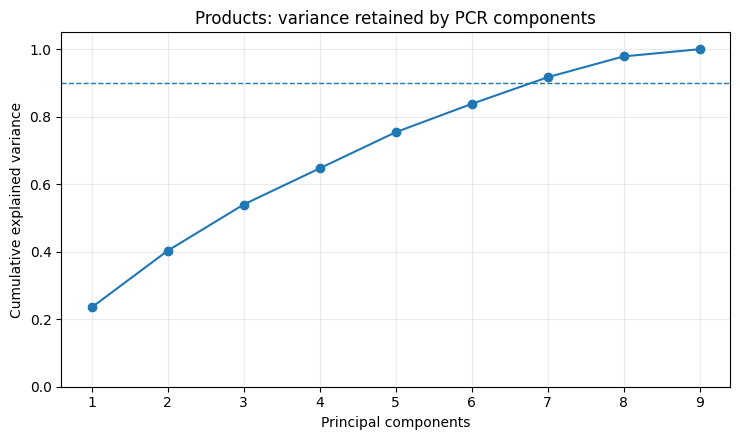

In [22]:
# Products cumulative explained variance.

products_pcr_curve = (
    component_curves["Products"]
    .query("Method == 'PCR'")
    .copy()
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(
    products_pcr_curve["n_components"],
    products_pcr_curve["Cumulative predictor variance"],
    marker="o",
)
ax.axhline(0.90, linestyle="--", linewidth=1)
ax.set_xlabel("Principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("Products: variance retained by PCR components")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

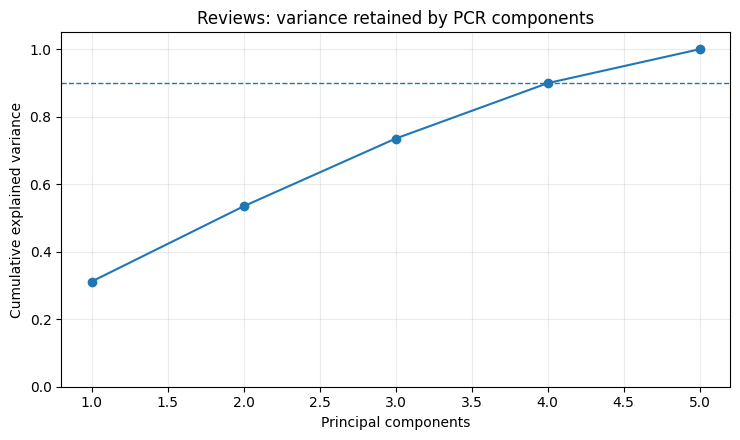

In [23]:
# Reviews cumulative explained variance.

reviews_pcr_curve = (
    component_curves["Reviews"]
    .query("Method == 'PCR'")
    .copy()
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(
    reviews_pcr_curve["n_components"],
    reviews_pcr_curve["Cumulative predictor variance"],
    marker="o",
)
ax.axhline(0.90, linestyle="--", linewidth=1)
ax.set_xlabel("Principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("Reviews: variance retained by PCR components")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. PCR versus PLSR component tuning

Now I compare predictive error as the number of retained components changes.

This is the Week 3 question I care about most for dimensionality reduction:

> Does the response-aware PLSR representation reach useful prediction with fewer components than PCR?

I keep the product and review charts separate because their outcomes have different RMSE scales.

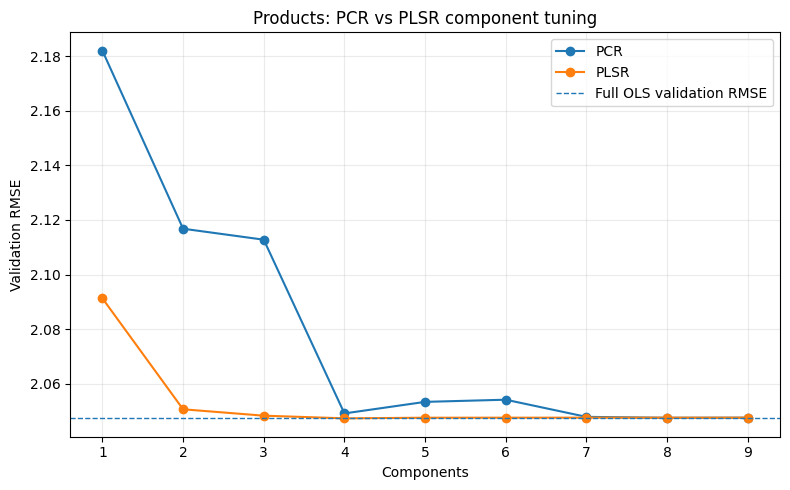

In [24]:
# Products PCR vs PLSR.

products_curve = component_curves["Products"]

fig, ax = plt.subplots(figsize=(8, 5))

for method_name in ["PCR", "PLSR"]:
    subset = products_curve[
        products_curve["Method"] == method_name
    ]

    ax.plot(
        subset["n_components"],
        subset["Validation RMSE"],
        marker="o",
        label=method_name,
    )

ax.axhline(
    component_results["Products"]["baseline_validation_RMSE"],
    linestyle="--",
    linewidth=1,
    label="Full OLS validation RMSE",
)

ax.set_xlabel("Components")
ax.set_ylabel("Validation RMSE")
ax.set_title("Products: PCR vs PLSR component tuning")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

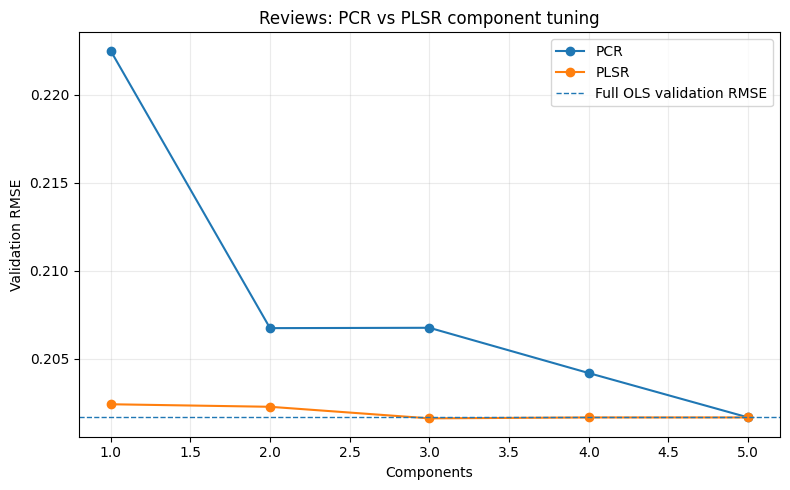

In [25]:
# Reviews PCR vs PLSR.

reviews_curve = component_curves["Reviews"]

fig, ax = plt.subplots(figsize=(8, 5))

for method_name in ["PCR", "PLSR"]:
    subset = reviews_curve[
        reviews_curve["Method"] == method_name
    ]

    ax.plot(
        subset["n_components"],
        subset["Validation RMSE"],
        marker="o",
        label=method_name,
    )

ax.axhline(
    component_results["Reviews"]["baseline_validation_RMSE"],
    linestyle="--",
    linewidth=1,
    label="Full OLS validation RMSE",
)

ax.set_xlabel("Components")
ax.set_ylabel("Validation RMSE")
ax.set_title("Reviews: PCR vs PLSR component tuning")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### What the component curves show

The pattern is different from the original single-dataset Week 3 notebook, but the same lecture concept is visible.

- For **Products**, PCR reaches its best validation result with more components than PLSR. PLSR gets to a similar validation error with a smaller representation.
- For **Reviews**, PLSR again reaches its best result with fewer components than PCR.

This supports the reason for PLSR in the first place: the directions with the greatest predictor variance are not automatically the directions that are most useful for predicting the outcome.

The differences in validation RMSE are small, so I would describe the result as an **efficiency advantage**, not a dramatic accuracy advantage.

## 12. Final PCR/PLSR comparison on the untouched test set

The component counts are now fixed using validation data.

I refit the preprocessing and each selected model on training plus validation data, then evaluate the final specifications on the test set.

I include the full OLS model as a reference because using all PCR components should approach the same linear-regression solution. The question is whether a smaller representation preserves most of that predictive performance.

In [26]:
component_test_rows = []
final_component_predictions = {}

for dataset_name, task in COMPONENT_TASKS.items():
    df = task["df"]
    info = component_results[dataset_name]

    train_validation_idx = np.concatenate(
        [info["train_idx"], info["validation_idx"]]
    )
    test_idx = info["test_idx"]

    features = task["numeric"] + task["categorical"]

    final_preprocessor = make_component_preprocessor(task)

    X_train_validation_raw = final_preprocessor.fit_transform(
        df.iloc[train_validation_idx][features]
    )
    X_test_raw = final_preprocessor.transform(
        df.iloc[test_idx][features]
    )

    final_scaler = StandardScaler()

    X_train_validation = final_scaler.fit_transform(
        X_train_validation_raw
    )
    X_test = final_scaler.transform(
        X_test_raw
    )

    y_train_validation = (
        df.iloc[train_validation_idx][task["target"]]
        .astype(float)
        .values
    )
    y_test = (
        df.iloc[test_idx][task["target"]]
        .astype(float)
        .values
    )

    # Full OLS
    ols = LinearRegression().fit(
        X_train_validation,
        y_train_validation,
    )

    ols_prediction = ols.predict(X_test)

    component_test_rows.append(
        {
            "Dataset": dataset_name,
            "Model": "Full OLS",
            "Complexity": X_train_validation.shape[1],
            "Variance retained": 1.0,
            **regression_metrics(y_test, ols_prediction),
        }
    )

    # PCR
    pcr_components = info["best_PCR_components"]

    pca = PCA(
        n_components=pcr_components
    ).fit(X_train_validation)

    pcr_model = LinearRegression().fit(
        pca.transform(X_train_validation),
        y_train_validation,
    )

    pcr_prediction = pcr_model.predict(
        pca.transform(X_test)
    )

    component_test_rows.append(
        {
            "Dataset": dataset_name,
            "Model": "PCR",
            "Complexity": pcr_components,
            "Variance retained": pca.explained_variance_ratio_.sum(),
            **regression_metrics(y_test, pcr_prediction),
        }
    )

    # PLSR
    plsr_components = info["best_PLSR_components"]

    plsr = PLSRegression(
        n_components=plsr_components,
        scale=False,
    ).fit(
        X_train_validation,
        y_train_validation,
    )

    plsr_prediction = plsr.predict(
        X_test
    ).ravel()

    component_test_rows.append(
        {
            "Dataset": dataset_name,
            "Model": "PLSR",
            "Complexity": plsr_components,
            "Variance retained": np.nan,
            **regression_metrics(y_test, plsr_prediction),
        }
    )

    final_component_predictions[
        (dataset_name, "PLSR")
    ] = (y_test, plsr_prediction)

component_test_results = pd.DataFrame(
    component_test_rows
)

display(component_test_results.round(4))

,Dataset,Model,Complexity,Variance retained,RMSE,MAE,R2
0,Products,Full OLS,9,1.0000,2.1049,1.6381,0.2338
1,Products,PCR,8,0.9778,2.1048,1.6378,0.2339
2,Products,PLSR,4,NaN,2.1049,1.6380,0.2338
3,Reviews,Full OLS,5,1.0000,0.2033,0.1504,0.1262
4,Reviews,PCR,5,1.0000,0.2033,0.1504,0.1262
5,Reviews,PLSR,3,NaN,0.2031,0.1503,0.1279


Model,Full OLS,PCR,PLSR
Dataset,,,
Products,9,8,4
Reviews,5,5,3


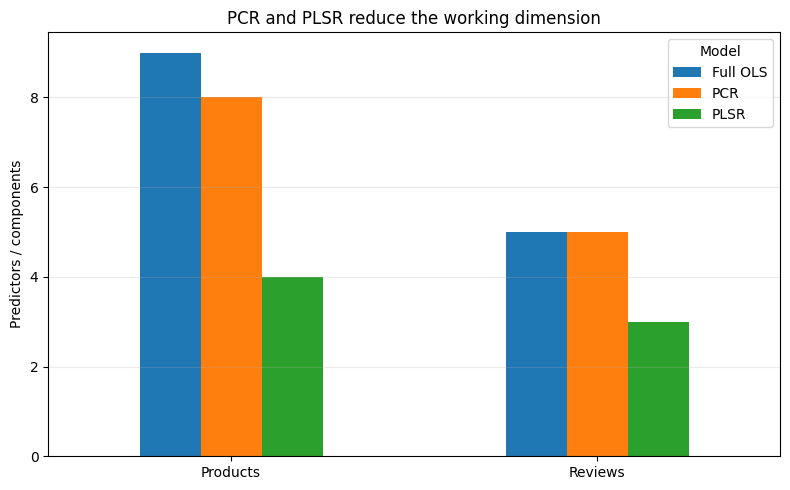

In [27]:
# Complexity comparison: how many dimensions are kept?

component_complexity = (
    component_test_results[
        component_test_results["Model"].isin(
            ["Full OLS", "PCR", "PLSR"]
        )
    ]
    .pivot(
        index="Dataset",
        columns="Model",
        values="Complexity",
    )
)

display(component_complexity)

ax = component_complexity.plot(
    kind="bar",
    figsize=(8, 5),
)
ax.set_xlabel("")
ax.set_ylabel("Predictors / components")
ax.set_title("PCR and PLSR reduce the working dimension")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

,Dataset,Model,RMSE % change vs Full OLS
0,Products,Full OLS,0.0000
1,Products,PCR,-0.0080
2,Products,PLSR,-0.0000
3,Reviews,Full OLS,0.0000
4,Reviews,PCR,0.0000
5,Reviews,PLSR,-0.1010


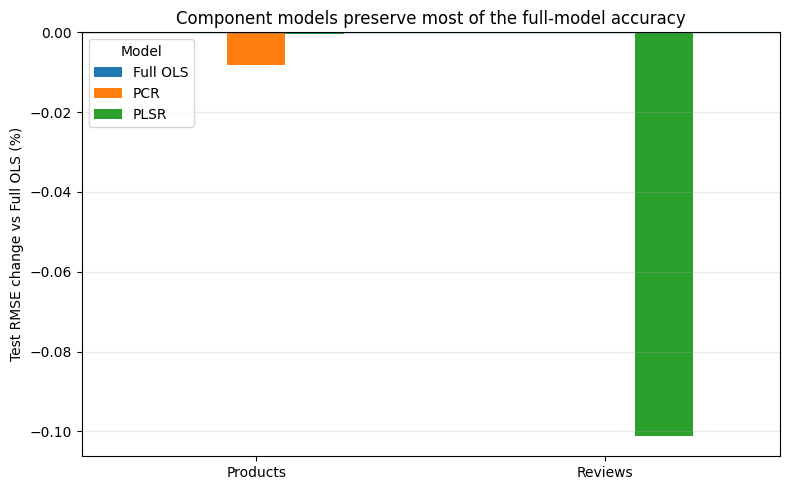

In [28]:
# Relative test RMSE keeps the comparison honest across different target scales.

relative_rows = []

for dataset_name in COMPONENT_TASKS:
    subset = component_test_results[
        component_test_results["Dataset"] == dataset_name
    ]

    ols_rmse = subset.loc[
        subset["Model"] == "Full OLS",
        "RMSE",
    ].iloc[0]

    for _, row in subset.iterrows():
        relative_rows.append(
            {
                "Dataset": dataset_name,
                "Model": row["Model"],
                "RMSE % change vs Full OLS": (
                    (row["RMSE"] - ols_rmse)
                    / ols_rmse
                ) * 100,
            }
        )

relative_component_rmse = pd.DataFrame(relative_rows)

display(relative_component_rmse.round(3))

pivot_relative = relative_component_rmse.pivot(
    index="Dataset",
    columns="Model",
    values="RMSE % change vs Full OLS",
)

ax = pivot_relative.plot(
    kind="bar",
    figsize=(8, 5),
)
ax.axhline(0, linewidth=1)
ax.set_xlabel("")
ax.set_ylabel("Test RMSE change vs Full OLS (%)")
ax.set_title("Component models preserve most of the full-model accuracy")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### PCR and PLSR decision

The final test errors remain close to the full linear model.

That means dimensionality reduction is mainly buying **compactness**, not a dramatic accuracy gain.

PLSR is the more attractive compact representation in both tables because it reaches comparable performance with fewer components. PCR remains useful when preserving high-variance structure itself is important, but for these two supervised prediction tasks the response-aware PLSR representation is more efficient.

## 13. A closer look at the compact PLSR predictions

A compact model can have a good average RMSE while still missing certain regions of the outcome.

I plot actual versus predicted values for the two PLSR test sets. Perfect predictions would fall on the diagonal.

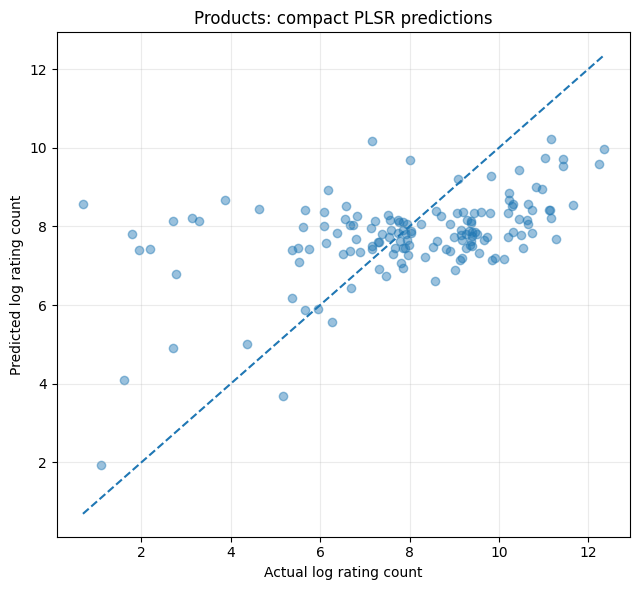

In [29]:
# Product PLSR actual vs predicted.

product_actual, product_prediction = final_component_predictions[
    ("Products", "PLSR")
]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(
    product_actual,
    product_prediction,
    alpha=0.45,
)

low = min(product_actual.min(), product_prediction.min())
high = max(product_actual.max(), product_prediction.max())

ax.plot(
    [low, high],
    [low, high],
    linestyle="--",
)

ax.set_xlabel("Actual log rating count")
ax.set_ylabel("Predicted log rating count")
ax.set_title("Products: compact PLSR predictions")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

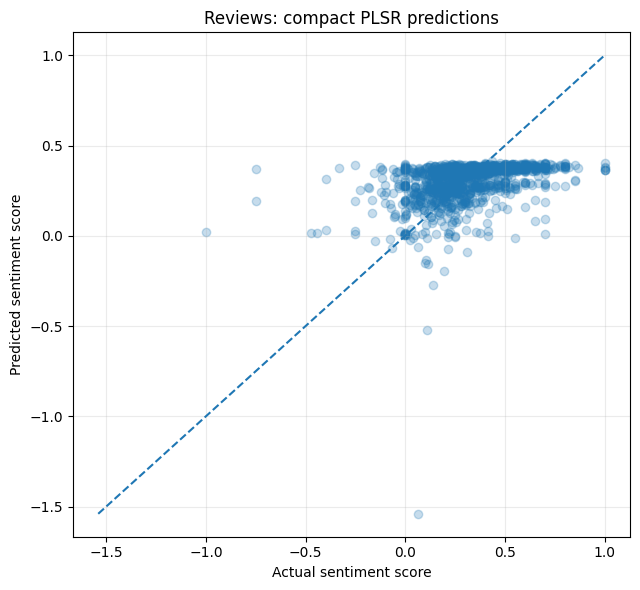

In [30]:
# Review PLSR actual vs predicted.

review_actual, review_prediction = final_component_predictions[
    ("Reviews", "PLSR")
]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(
    review_actual,
    review_prediction,
    alpha=0.25,
)

low = min(review_actual.min(), review_prediction.min())
high = max(review_actual.max(), review_prediction.max())

ax.plot(
    [low, high],
    [low, high],
    linestyle="--",
)

ax.set_xlabel("Actual sentiment score")
ax.set_ylabel("Predicted sentiment score")
ax.set_title("Reviews: compact PLSR predictions")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 14. What I found

Week 3 produced two different kinds of simplification.

### Forward and backward selection

Both methods selected the same final subset for each of the two interpretable regression problems.

For behavior, the model reduces to the transaction economics variables `Sales`, `Quantity`, and `Discount`. For churn-table `OrderCount`, both directions retain the same seven activity-related variables.

The main benefit is interpretability. The selected models stay close to the full-model test performance while exposing a smaller set of original business variables.

### PCR

PCR reduces the predictor matrix by keeping high-variance directions. It works, but the component count needed for the best validation result is not necessarily very small because variance in `X` is not the same as predictive value for `Y`.

### PLSR

PLSR reaches a similar test result with fewer components in both Products and Reviews. That is the most important dimensionality-reduction finding from this version of the project.

### Which approach would I keep?

- For **stakeholder-facing explanations**, I prefer forward/backward selection because the retained variables remain directly interpretable.
- For a **compact predictive representation**, I prefer PLSR because it keeps fewer dimensions while preserving most of the full-model accuracy.
- I would use PCR when the high-variance structure of the predictors is itself important, but it is not my first choice for these two supervised prediction tasks.

The four datasets therefore contribute complementary evidence rather than repeating the same modeling exercise.

## 15. How I controlled overfitting

I used several safeguards:

1. The test set was separated before any feature or component selection.
2. Forward/backward model size was chosen using validation RMSE.
3. PCR and PLSR component counts were also chosen using validation RMSE.
4. Preprocessing was fit on training data during model selection.
5. The selected specifications were refit on training plus validation only after the choices were fixed.
6. Group-aware splitting was used for behavior customers and review products.
7. I did not repeatedly inspect the test set while tuning model size.

I also avoided using repeated ordinary p-values as the stepwise decision rule. Searching many candidate models changes the usual interpretation of those p-values, so validation performance is a cleaner selection criterion here.

## 16. Limitations

- Stepwise selection is greedy and may miss a better subset that lies outside its search path.
- Agreement between forward and backward selection increases confidence but does not prove optimality.
- `OrderCount` is a count outcome, so linear regression is still an approximation.
- PCR components are mathematically compact but harder to explain than original variables.
- PLSR components are even more outcome-oriented, which helps prediction but reduces direct interpretability.
- The product dataset is much smaller than the behavior and review tables, so its validation curve is more sensitive to the exact split.
- Structured review metadata explains only part of sentiment variation. The review text itself likely contains additional signal.
- The models are predictive associations, not causal estimates.

## 17. Source and reproducibility notes

### Course sources

- DX799 O1, Week 3 Overview
- Week 3 lesson: **Principal Component Regression and Partial Least Squares Regression**
- Week 3 Jupyter Notebook: **Linear Regression 3**

The course lesson is the basis for the distinctions used here: PCR chooses components from predictor variance, PLSR uses the response while constructing components, and standardization is important before applying component methods.

### External reference

scikit-learn developers, **Decomposition and Cross Decomposition User Guides**  
https://scikit-learn.org/stable/modules/decomposition.html  
https://scikit-learn.org/stable/modules/cross_decomposition.html

These are primary documentation sources for the PCA and PLSRegression implementations used in the notebook.

### Reproducibility

- Random seed: 42
- Final test share: 20%
- Validation share: 20% of the full dataset
- Stepwise decision metric: validation RMSE
- PCR/PLSR component decision metric: validation RMSE
- Numeric predictors are standardized
- Behavior split is grouped by `Customer ID`
- Review split is grouped by `productASIN`
- Test data are evaluated only after model-size decisions are fixed

In [31]:
# Save a compact summary for Milestone One synthesis.

Path("outputs").mkdir(exist_ok=True)

summary = {
    "week": 3,
    "topic": "Forward/backward selection, PCR, and PLSR",
    "stepwise_test_results": stepwise_test_results.to_dict(
        orient="records"
    ),
    "component_test_results": component_test_results.to_dict(
        orient="records"
    ),
    "selected_features": {
        dataset_name: {
            "forward": info["forward_best"]["features"],
            "backward": info["backward_best"]["features"],
        }
        for dataset_name, info in stepwise_results.items()
    },
    "selected_components": {
        dataset_name: {
            "PCR": info["best_PCR_components"],
            "PLSR": info["best_PLSR_components"],
        }
        for dataset_name, info in component_results.items()
    },
}

Path("outputs/week3_summary.json").write_text(
    json.dumps(summary, indent=2)
)

print("Saved outputs/week3_summary.json")

Saved outputs/week3_summary.json
